# Comparación de rendimiento: LMS vs. RLS (Proyecto 1 vs. Proyecto 2)

Este notebook **no optimiza nada**: toma los hiperparámetros ya obtenidos (LMS/NLMS/VS-LMS del Proyecto 1 y el RLS optimizado del Proyecto 2) y los compara sobre `IEEEPPG_TEST.ts` con gráficos del mismo estilo que la presentación del Proyecto 1.

**Qué incluye**

| # | Sección | Pregunta que responde |
|---|---|---|
| 1 | Tabla resumen + IC 95 % | ¿Cuánto mejora RLS y esa mejora es real o ruido? |
| 2 | Dispersión BPM estimado vs. real (por sujeto) | ¿Dónde acierta/falla cada método? (igual que la diapositiva 13) |
| 3 | CDF del error y comparación ventana a ventana | ¿Mejora la mediana, la cola de outliers, o ambas? |
| 4 | AAE por sujeto | ¿La mejora es general o depende de pocos sujetos? |
| 5 | Curvas de convergencia y costo computacional | ¿RLS converge más rápido? ¿A qué costo? |
| 6 | Casos concretos (ventana #481, mejor y peor caso de RLS) | Análisis cualitativo (igual que la diapositiva 14) |
| 7 | Ablación + sensibilidad de RLS | **¿La mejora viene de RLS o de los taps dilatados / regularización?** |

**Dos controles de justicia** que conviene mencionar en la presentación:
- Cada método se evalúa con *su* detector óptimo **y** con un detector común (periodograma Hann, nfft = 8192), para aislar el efecto del filtro adaptativo.
- La ablación y la sensibilidad se corren sobre **ventanas de entrenamiento**, no de test, para no "mirar" el test al tomar decisiones.



## CARGANDO LOS DATOS

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from IPython.display import display

# --- Resolución de rutas (mismo esquema que el notebook de optimización) ---
cwd = os.path.abspath(os.getcwd())
if os.path.basename(cwd) in ("implementation", "restructured_implementation"):
    IMPL_DIR, PROJECT_ROOT = cwd, os.path.abspath(os.path.join(cwd, ".."))
elif os.path.isdir(os.path.join(cwd, "implementation")):
    IMPL_DIR, PROJECT_ROOT = os.path.join(cwd, "implementation"), cwd
else:
    IMPL_DIR, PROJECT_ROOT = cwd, cwd
for p in (IMPL_DIR, PROJECT_ROOT):
    if p not in sys.path:
        sys.path.insert(0, p)

try:
    from implementation import (
        FS, WIN, load_ts, get_participant_groups, preprocess_signal,
        snr_weighted_late_fusion, zero_padded_periodogram_bpm,
        objective_function, HeartRateEstimatorModel,
    )
    from implementation import LMS_algorithms as LMSA
except ImportError:
    from dataset_preparation import FS, WIN, load_ts, get_participant_groups
    from preprocessing import preprocess_signal
    from fusion import snr_weighted_late_fusion
    from bpm_detection import zero_padded_periodogram_bpm, objective_function
    from pipeline import HeartRateEstimatorModel
    import LMS_algorithms as LMSA

plt.rcParams.update({
    "figure.figsize": (13, 5), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


def find_dataset_file(filename):
    search_dirs = [
        os.getcwd(), PROJECT_ROOT, IMPL_DIR,
        os.path.join(PROJECT_ROOT, "Proyecto_1_submission"),
        "/content", "/content/drive/MyDrive",
    ]
    for d in search_dirs:
        cand = os.path.join(d, filename)
        if os.path.isfile(cand):
            return cand
    raise FileNotFoundError(f"No se encontró '{filename}' en {search_dirs}")


X_train, y_train = load_ts(find_dataset_file("IEEEPPG_TRAIN.ts"))
X_test, y_test = load_ts(find_dataset_file("IEEEPPG_TEST.ts"))
train_groups = get_participant_groups(X_train)
test_groups = get_participant_groups(X_test)
subjects = np.unique(test_groups)

print(f"Train: {X_train.shape} | sujetos = {len(np.unique(train_groups))}")
print(f"Test : {X_test.shape} | sujetos = {len(subjects)}")

Train: (1768, 5, 1000) | sujetos = 12
Test : (1328, 5, 1000) | sujetos = 10


## 1. Configuración de los modelos comparados (Opción B: comparación justa)

- **LMS / NLMS / VS-LMS (Opción B)**: mantienen los pasos óptimos y órdenes de filtro obtenidos en el Proyecto 1, pero incorporan exactamente los mismos parámetros estructurales del pipeline que RLS (`delay_step`, `huber_c`, `warm_start_ratio`) para aislar la diferencia intrínseca entre algoritmos.
- **RLS**: ganador de la optimización del Proyecto 2 (5-fold por sujeto). Si volvés a correr la optimización, pegá acá el nuevo `best_hyperparameters`.

In [2]:
# ----------------------------- Configuración general -----------------------------
SEED = 0
SAVE_FIGS = True
FIG_DIR = "figuras_comparacion"
LMS_REF = "nlms"        # variante LMS usada como "la mejor del Proyecto 1" en las comparaciones pareadas
N_BOOT = 2000           # réplicas del bootstrap por sujeto
N_CURVE = 150           # ventanas de test para curvas de convergencia y tiempos
RUN_ABLATION = True     # ablación sobre ventanas de ENTRENAMIENTO
RUN_SENSITIVITY = True  # barrido de N_eff y delta sobre ventanas de ENTRENAMIENTO
ABL_N = 300             # ventanas de entrenamiento usadas en ablación / sensibilidad
OUTLIER_BPM = 10.0

os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(fig, name):
    if SAVE_FIGS:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")


# ----------------------------- RLS optimizado (Proyecto 2) -----------------------------
RLS_M = 7
RLS_PARAMS = dict(
    delay_step=4,
    N_eff=1409.281222670354,          # lam = 1 - 1/N_eff = 0.99929
    delta=5.11410341560248,
    diag_load=0.14339015026730578,
    huber_c=2.5014879715311853,
    warm_start_ratio=0.0,
)
RLS_HR = dict(hr_algorithm="periodogram", hr_params=dict(nfft=8192, window_type="hann"))

# ----------------------------- Opción B: características compartidas -------------------
SHARED_OPT_B = dict(
    delay_step=RLS_PARAMS["delay_step"],
    huber_c=RLS_PARAMS["huber_c"],
    warm_start_ratio=RLS_PARAMS["warm_start_ratio"],
)

models = {
    "lms": HeartRateEstimatorModel.from_project1_optimal("lms", **SHARED_OPT_B),
    "nlms": HeartRateEstimatorModel.from_project1_optimal("nlms", **SHARED_OPT_B),
    "vs_lms": HeartRateEstimatorModel.from_project1_optimal("vs_lms", **SHARED_OPT_B),
    "rls": HeartRateEstimatorModel(
        lms_algorithm="rls", M=RLS_M, lms_params=dict(RLS_PARAMS), **RLS_HR),
}

# Valores previos (Proyecto 1 sin Opción B) como referencia histórica
REF_TEST_AAE = {"base": 20.41, "lms": 16.01, "nlms": 14.05, "vs_lms": 15.76, "rls": 12.23}
CV_AAE = {"base": 12.52, "lms": 5.18, "nlms": 4.72, "vs_lms": 4.56, "rls": 3.66}

ORDER = ["base", "lms", "nlms", "vs_lms", "rls"]
LABELS = {"base": "Sin filtro", "lms": "LMS", "nlms": "NLMS", "vs_lms": "VS-LMS", "rls": "RLS"}
COLORS = {"base": "#7f7f7f", "lms": "#9467bd", "nlms": "#1f77b4", "vs_lms": "#2ca02c", "rls": "#d62728"}
assert LMS_REF in models

## 2. Evaluación sobre el conjunto de test

Cada ventana de 8 s se procesa de forma independiente (igual que en el Proyecto 1). Se calculan dos juegos de predicciones:

- **detector propio**: el detector óptimo de cada método (lo que reportó cada optimización).
- **detector común**: periodograma Hann, nfft = 8192 para *todos*. Aísla el efecto del filtro adaptativo.

Si alguna ventana diverge (salida `NaN`), se reemplaza por la predicción sin filtro y se informa cuántas fueron.

In [3]:
def compute_metrics(y_hat, y_true):
    e = np.abs(y_hat - y_true)
    return dict(
        aae=float(np.mean(e)), rmse=float(np.sqrt(np.mean(e ** 2))),
        medae=float(np.median(e)), outlier_pct=float(np.mean(e > OUTLIER_BPM) * 100),
        obj=float(objective_function(y_hat, y_true)),
    )


def fill_nan(p, fallback):
    p = np.asarray(p, dtype=float).copy()
    bad = ~np.isfinite(p)
    p[bad] = fallback[bad]
    return p, int(bad.sum())


# --- Línea base: sin filtro adaptativo (PPG1+PPG2 fusionadas por SNR) ---
ppg1_t, ppg2_t, acc_t = preprocess_signal(X_test)
d_fused_t = np.array([snr_weighted_late_fusion(ppg1_t[i], ppg2_t[i]) for i in range(len(X_test))])
pred_base = np.array([zero_padded_periodogram_bpm(s, nfft=8192) for s in d_fused_t])

test_eval = {"base": {"preds": pred_base, "preds_common": pred_base, "signals": d_fused_t, "n_nan": 0}}

for key, model in models.items():
    t0 = time.perf_counter()
    preds, sigs = model.predict_with_signals(X_test)
    elapsed = time.perf_counter() - t0
    common = np.array([zero_padded_periodogram_bpm(s, nfft=8192, window_type="hann") for s in sigs])
    preds, n1 = fill_nan(preds, pred_base)
    common, n2 = fill_nan(common, pred_base)
    test_eval[key] = {"preds": preds, "preds_common": common, "signals": sigs, "n_nan": max(n1, n2)}
    print(f"{LABELS[key]:<7} listo en {elapsed:6.1f} s  (ventanas con NaN reemplazadas: {max(n1, n2)})")

for key, ev in test_eval.items():
    ev.update(compute_metrics(ev["preds"], y_test))
    ev["abs_err"] = np.abs(ev["preds"] - y_test)
    ev["abs_err_common"] = np.abs(ev["preds_common"] - y_test)
    ev["common"] = compute_metrics(ev["preds_common"], y_test)

LMS     listo en   14.1 s  (ventanas con NaN reemplazadas: 0)


NLMS    listo en   14.4 s  (ventanas con NaN reemplazadas: 0)


VS-LMS  listo en   15.2 s  (ventanas con NaN reemplazadas: 0)


RLS     listo en   29.6 s  (ventanas con NaN reemplazadas: 0)


In [4]:
# ----------------------------- Tabla resumen -----------------------------
rows = []
for k in ORDER:
    ev = test_eval[k]
    rows.append({
        "Método": LABELS[k],
        "AAE val. (CV)": CV_AAE[k],
        "AAE test": ev["aae"],
        "RMSE test": ev["rmse"],
        "Error mediano": ev["medae"],
        "Outliers (%)": ev["outlier_pct"],
        "AAE test (det. común)": ev["common"]["aae"],
        "Outliers % (det. común)": ev["common"]["outlier_pct"],
    })
df = pd.DataFrame(rows).set_index("Método")

try:
    filt = [LABELS[k] for k in ORDER if k != "base"]
    display(
        df.style.format("{:.2f}")
        .highlight_min(subset=pd.IndexSlice[filt, df.columns[1:]], color="#c6efce")
        .set_caption("Test (IEEEPPG_TEST.ts), valores en BPM. Verde = mejor entre los métodos con filtro.")
    )
except Exception:
    print(df.round(2).to_string())

print("\nComparación vs. línea base histórica sin Opción B (AAE test):")
for k in ORDER:
    diff = test_eval[k]["aae"] - REF_TEST_AAE[k]
    print(f"  {LABELS[k]:<10} histórico (sin Opción B) {REF_TEST_AAE[k]:6.2f} | Opción B {test_eval[k]['aae']:6.2f} | dif {diff:+.2f} BPM")

,AAE val. (CV),AAE test,RMSE test,Error mediano,Outliers (%),AAE test (det. común),Outliers % (det. común)
Método,,,,,,,
Sin filtro,12.52,20.41,34.93,3.29,41.11,20.41,41.11
LMS,5.18,13.09,29.27,1.39,21.99,13.92,23.27
NLMS,4.72,13.41,28.82,1.55,24.02,13.38,24.17
VS-LMS,4.56,13.94,29.51,1.60,24.40,14.17,25.00
RLS,3.66,12.23,27.53,1.44,21.54,12.23,21.54



Comparación vs. línea base histórica sin Opción B (AAE test):
  Sin filtro histórico (sin Opción B)  20.41 | Opción B  20.41 | dif -0.00 BPM
  LMS        histórico (sin Opción B)  16.01 | Opción B  13.09 | dif -2.92 BPM
  NLMS       histórico (sin Opción B)  14.05 | Opción B  13.41 | dif -0.64 BPM
  VS-LMS     histórico (sin Opción B)  15.76 | Opción B  13.94 | dif -1.82 BPM
  RLS        histórico (sin Opción B)  12.23 | Opción B  12.23 | dif +0.00 BPM


AEE - Error absoulto medio (cada error de bpm calculado y divido por la cantidad de estimaciones)
RMSE - Error absolute al cuadrado y despues sqrt - castigada errores mas grandes

## 3. ¿La mejora es real? Intervalos de confianza por bootstrap **por sujeto**

Las ventanas de un mismo sujeto están muy correlacionadas (se solapan 6 s de 8 s), así que remuestrear ventanas sueltas daría intervalos demasiado optimistas. Acá se remuestrean **sujetos completos** (bootstrap por clusters, 95 %). Con solo 10 sujetos de test los intervalos van a ser anchos; eso es información honesta, no un defecto.

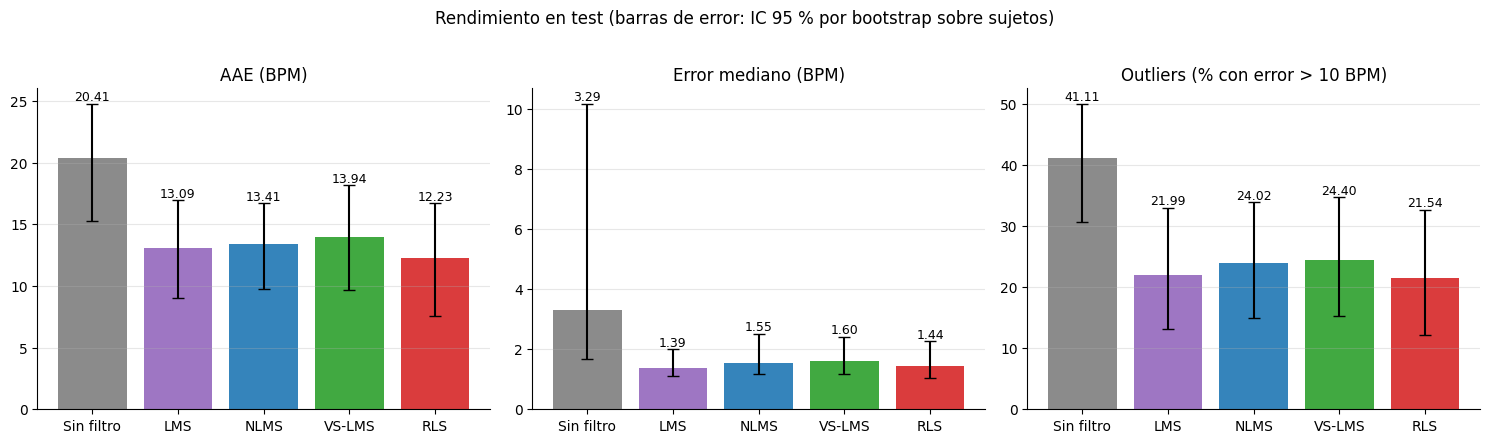

Diferencia pareada de AAE por ventana (positiva = RLS mejor), IC 95 % por sujeto:
  LMS     - RLS :  +0.86 BPM  [-0.93, +2.90]   (el IC incluye 0 -> no concluyente)  | RLS mejor en 36.1% de las ventanas
  NLMS    - RLS :  +1.17 BPM  [-0.65, +3.23]   (el IC incluye 0 -> no concluyente)  | RLS mejor en 39.2% de las ventanas
  VS-LMS  - RLS :  +1.71 BPM  [-0.22, +3.92]   (el IC incluye 0 -> no concluyente)  | RLS mejor en 36.2% de las ventanas


In [5]:
def cluster_bootstrap_ci(values, groups, stat=np.mean, n_boot=N_BOOT, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups)
    parts = [values[groups == g] for g in ug]
    out = np.empty(n_boot)
    for b in range(n_boot):
        sel = rng.integers(0, len(ug), len(ug))
        out[b] = stat(np.concatenate([parts[j] for j in sel]))
    return float(stat(values)), np.percentile(out, [100 * alpha / 2, 100 * (1 - alpha / 2)])


stats = [
    ("AAE (BPM)", np.mean),
    ("Error mediano (BPM)", np.median),
    (f"Outliers (% con error > {OUTLIER_BPM:g} BPM)", lambda v: 100.0 * np.mean(v > OUTLIER_BPM)),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (title, stat) in zip(axes, stats):
    for j, k in enumerate(ORDER):
        val, (lo, hi) = cluster_bootstrap_ci(test_eval[k]["abs_err"], test_groups, stat)
        ax.bar(j, val, color=COLORS[k], yerr=[[val - lo], [hi - val]], capsize=4, alpha=0.9)
        ax.text(j, hi, f"{val:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(ORDER)))
    ax.set_xticklabels([LABELS[k] for k in ORDER])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Rendimiento en test (barras de error: IC 95 % por bootstrap sobre sujetos)", y=1.02)
fig.tight_layout()
save_fig(fig, "01_barras_metricas_IC")
plt.show()

print("Diferencia pareada de AAE por ventana (positiva = RLS mejor), IC 95 % por sujeto:")
for k in ["lms", "nlms", "vs_lms"]:
    diff = test_eval[k]["abs_err"] - test_eval["rls"]["abs_err"]
    m, (lo, hi) = cluster_bootstrap_ci(diff, test_groups, np.mean)
    verdict = "el IC excluye 0" if (lo > 0 or hi < 0) else "el IC incluye 0 -> no concluyente"
    print(f"  {LABELS[k]:<7} - RLS : {m:+6.2f} BPM  [{lo:+.2f}, {hi:+.2f}]   ({verdict})  "
          f"| RLS mejor en {np.mean(diff > 0) * 100:4.1f}% de las ventanas")

## 4. Dispersión de BPM estimado vs. real, coloreada por sujeto

Mismo formato que la diapositiva 13. La diagonal es la estimación perfecta y la banda rosada marca ±10 BPM (fuera de ella la ventana cuenta como outlier). Los **armónicos** se ven como líneas paralelas a la diagonal en 2× o 0,5× el BPM real.

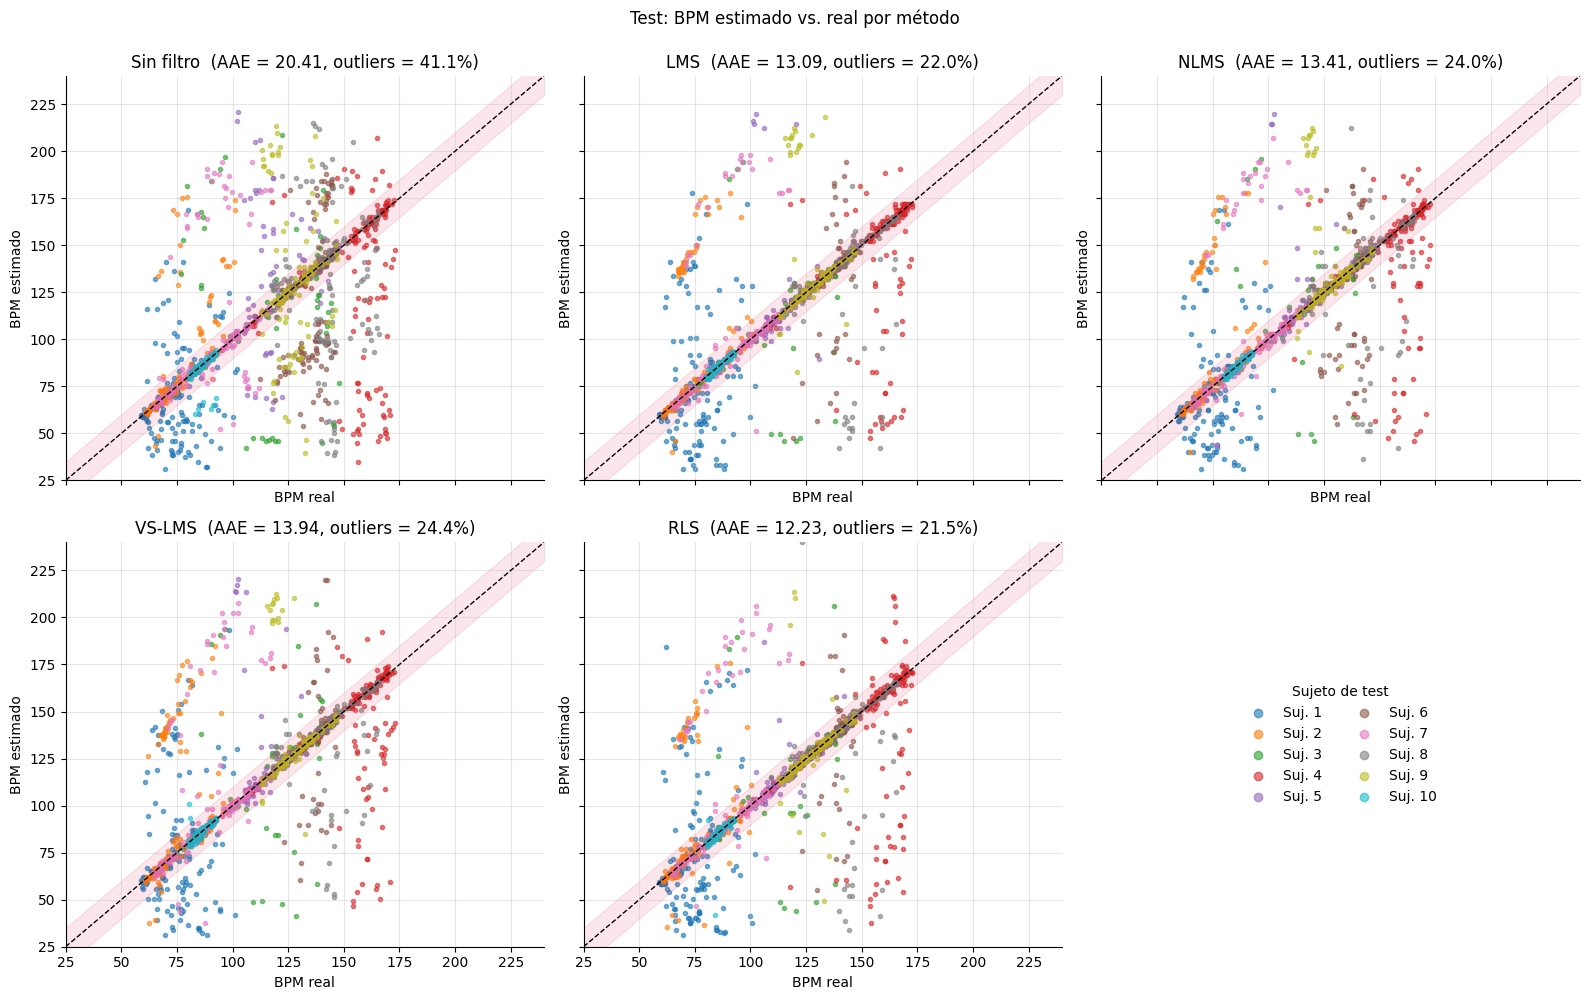

In [6]:
cmap = plt.get_cmap("tab10")
lim = (25, 240)
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
axf = axes.ravel()
for ax, k in zip(axf, ORDER):
    for s in subjects:
        idx = test_groups == s
        ax.scatter(y_test[idx], test_eval[k]["preds"][idx], s=9, alpha=0.6, color=cmap(s % 10),
                   label=f"Suj. {s + 1}")
    xs = np.array(lim)
    ax.plot(xs, xs, "k--", lw=1)
    ax.fill_between(xs, xs - OUTLIER_BPM, xs + OUTLIER_BPM, color="crimson", alpha=0.10)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{LABELS[k]}  (AAE = {test_eval[k]['aae']:.2f}, outliers = {test_eval[k]['outlier_pct']:.1f}%)")
    ax.set_xlabel("BPM real")
    ax.set_ylabel("BPM estimado")
h, l = axf[0].get_legend_handles_labels()
axf[-1].axis("off")
axf[-1].legend(h, l, loc="center", ncol=2, title="Sujeto de test", frameon=False, markerscale=2)
fig.suptitle("Test: BPM estimado vs. real por método", y=0.995)
fig.tight_layout()
save_fig(fig, "02_dispersion_por_metodo")
plt.show()

## 5. Distribución del error y comparación ventana a ventana

- **Izquierda (CDF del error absoluto):** una curva más a la izquierda/arriba es mejor. Permite ver de un vistazo si la mejora está en la *mediana* (zona de 1–3 BPM) o en la *cola* de outliers (cruce con la línea de 10 BPM).
- **Derecha (pareado):** cada punto es una ventana. Por debajo de la diagonal, RLS tiene menos error que la variante LMS de referencia; por encima, más.

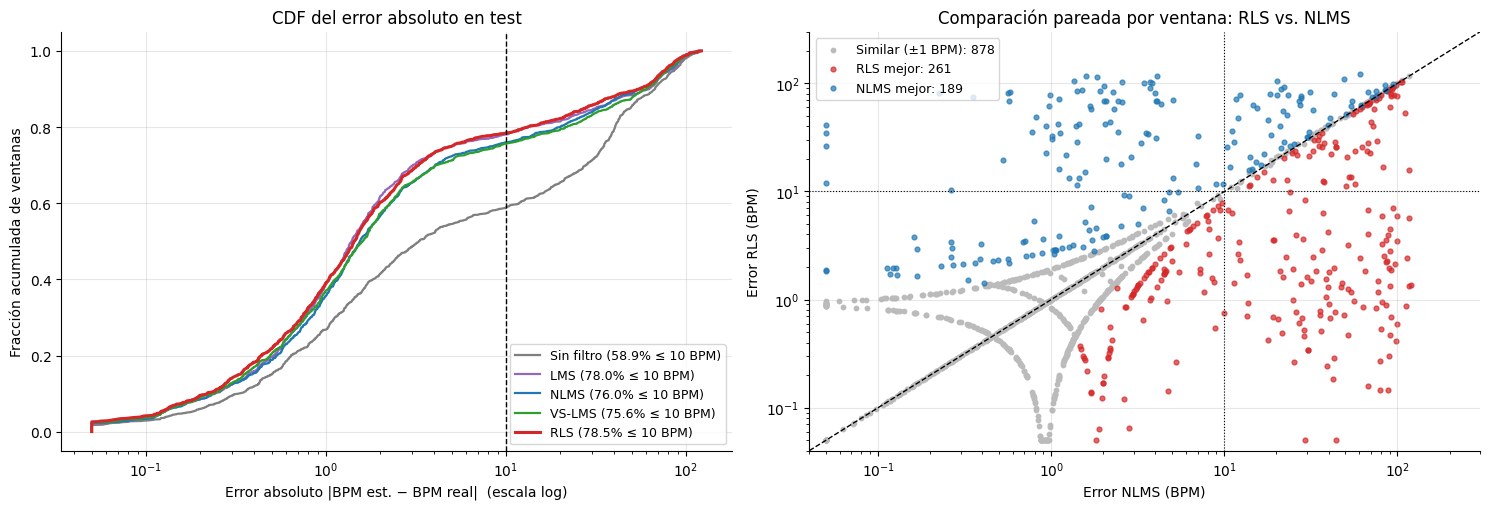

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

ax = axes[0]
for k in ORDER:
    e = np.sort(test_eval[k]["abs_err"])
    ax.plot(np.maximum(e, 0.05), np.arange(1, len(e) + 1) / len(e), color=COLORS[k], lw=2.2 if k == "rls" else 1.6,
            label=f"{LABELS[k]} ({100 - test_eval[k]['outlier_pct']:.1f}% ≤ {OUTLIER_BPM:g} BPM)")
ax.axvline(OUTLIER_BPM, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Error absoluto |BPM est. − BPM real|  (escala log)")
ax.set_ylabel("Fracción acumulada de ventanas")
ax.set_title("CDF del error absoluto en test")
ax.legend(loc="lower right", fontsize=9)

ax = axes[1]
e_ref = np.maximum(test_eval[LMS_REF]["abs_err"], 0.05)
e_rls = np.maximum(test_eval["rls"]["abs_err"], 0.05)
better = test_eval["rls"]["abs_err"] < test_eval[LMS_REF]["abs_err"] - 1.0
worse = test_eval["rls"]["abs_err"] > test_eval[LMS_REF]["abs_err"] + 1.0
same = ~better & ~worse
ax.scatter(e_ref[same], e_rls[same], s=10, color="#bbbbbb", label=f"Similar (±1 BPM): {same.sum()}")
ax.scatter(e_ref[better], e_rls[better], s=12, color=COLORS["rls"], alpha=0.7, label=f"RLS mejor: {better.sum()}")
ax.scatter(e_ref[worse], e_rls[worse], s=12, color=COLORS[LMS_REF], alpha=0.7, label=f"{LABELS[LMS_REF]} mejor: {worse.sum()}")
lims = (0.04, 300)
ax.plot(lims, lims, "k--", lw=1)
ax.axvline(OUTLIER_BPM, color="k", ls=":", lw=0.8); ax.axhline(OUTLIER_BPM, color="k", ls=":", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(f"Error {LABELS[LMS_REF]} (BPM)")
ax.set_ylabel("Error RLS (BPM)")
ax.set_title(f"Comparación pareada por ventana: RLS vs. {LABELS[LMS_REF]}")
ax.legend(loc="upper left", fontsize=9)

fig.tight_layout()
save_fig(fig, "03_cdf_y_pareado")
plt.show()

## 6. Rendimiento por sujeto

Responde si la mejora es general o la explican pocos sujetos. A la derecha: `AAE(variante LMS de referencia) − AAE(RLS)` por sujeto; verde = RLS mejor, rojo = RLS peor.

,Ventanas,Sin filtro,LMS,NLMS,VS-LMS,RLS
Sujeto 1,142,19.43,23.64,21.74,25.46,25.02
Sujeto 2,137,11.15,20.95,16.66,23.18,15.60
Sujeto 3,144,16.01,6.89,7.34,8.75,6.78
Sujeto 4,152,31.53,18.01,19.15,18.22,20.10
Sujeto 5,101,18.55,7.69,6.70,9.61,3.44
Sujeto 6,157,24.83,7.56,12.53,8.54,6.04
Sujeto 7,132,21.55,16.01,18.53,19.05,19.35
Sujeto 8,142,28.47,12.30,13.09,9.55,12.90
Sujeto 9,121,23.49,12.47,11.86,11.42,5.84
Sujeto 10,100,2.13,0.94,0.84,1.27,1.33


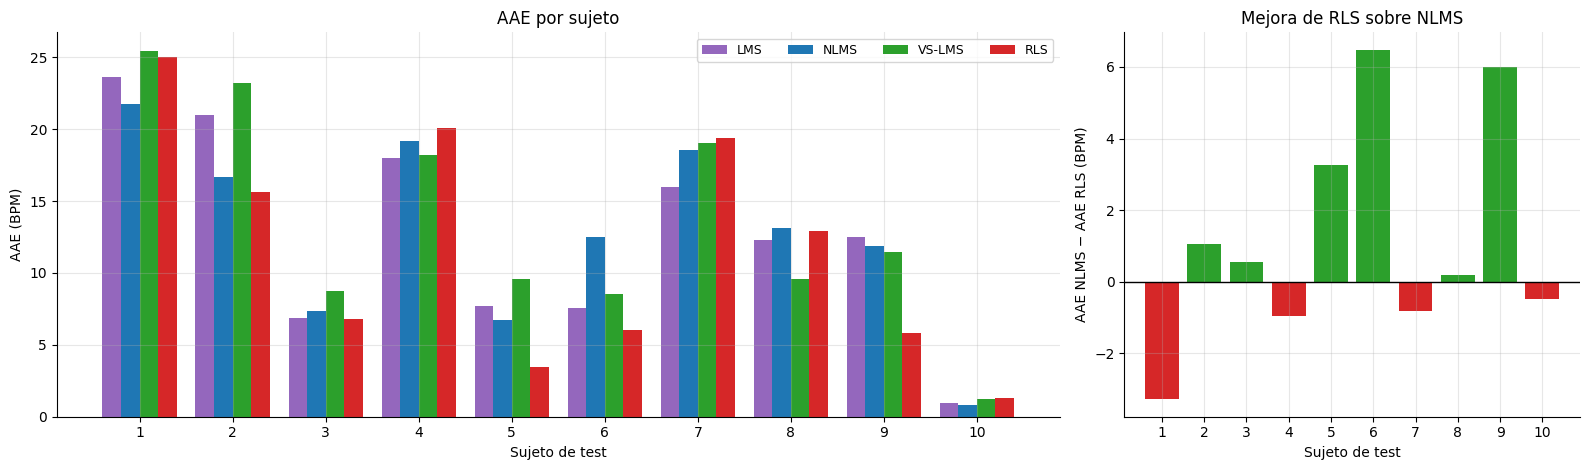

RLS mejora a NLMS en 6 de 10 sujetos.


In [8]:
aae_subj = pd.DataFrame(
    {LABELS[k]: [test_eval[k]["abs_err"][test_groups == s].mean() for s in subjects] for k in ORDER},
    index=[f"Sujeto {s + 1}" for s in subjects],
)
aae_subj.insert(0, "Ventanas", [int(np.sum(test_groups == s)) for s in subjects])
display(aae_subj.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
cmp_keys = ["lms", "nlms", "vs_lms", "rls"]
wbar = 0.2
for j, k in enumerate(cmp_keys):
    ax.bar(subjects + 1 + (j - 1.5) * wbar, aae_subj[LABELS[k]].values, width=wbar, color=COLORS[k], label=LABELS[k])
ax.set_xticks(subjects + 1)
ax.set_xlabel("Sujeto de test")
ax.set_ylabel("AAE (BPM)")
ax.set_title("AAE por sujeto")
ax.legend(ncol=4, fontsize=9)

ax = axes[1]
gain = aae_subj[LABELS[LMS_REF]].values - aae_subj["RLS"].values
ax.bar(subjects + 1, gain, color=np.where(gain > 0, "#2ca02c", "#d62728"))
ax.axhline(0, color="k", lw=1)
ax.set_xticks(subjects + 1)
ax.set_xlabel("Sujeto de test")
ax.set_ylabel(f"AAE {LABELS[LMS_REF]} − AAE RLS (BPM)")
ax.set_title(f"Mejora de RLS sobre {LABELS[LMS_REF]}")

fig.tight_layout()
save_fig(fig, "04_aae_por_sujeto")
plt.show()
print(f"RLS mejora a {LABELS[LMS_REF]} en {int(np.sum(gain > 0))} de {len(subjects)} sujetos.")

## 7. Convergencia y costo computacional

**Curvas de convergencia:** potencia media del residuo `e[n]` (la PPG "limpia") en función del tiempo dentro de la ventana, mediana sobre ventanas de test, en dB respecto de la potencia de la PPG de entrada (que está normalizada a varianza 1). Como `e[n]` conserva la señal cardíaca, la curva **no baja a cero**: lo que importa es qué tan rápido llega a su piso y cuánto vale ese piso. El resto de la potencia residual es sobre todo el latido, que es lo que queremos conservar.

**Costo:** RLS cuesta O(L²) por muestra contra O(L) de los LMS, donde `L = 3M` es la cantidad de pesos. Con el `M` elegido, RLS tiene menos pesos (L = 21), lo que compensa parte de la diferencia.

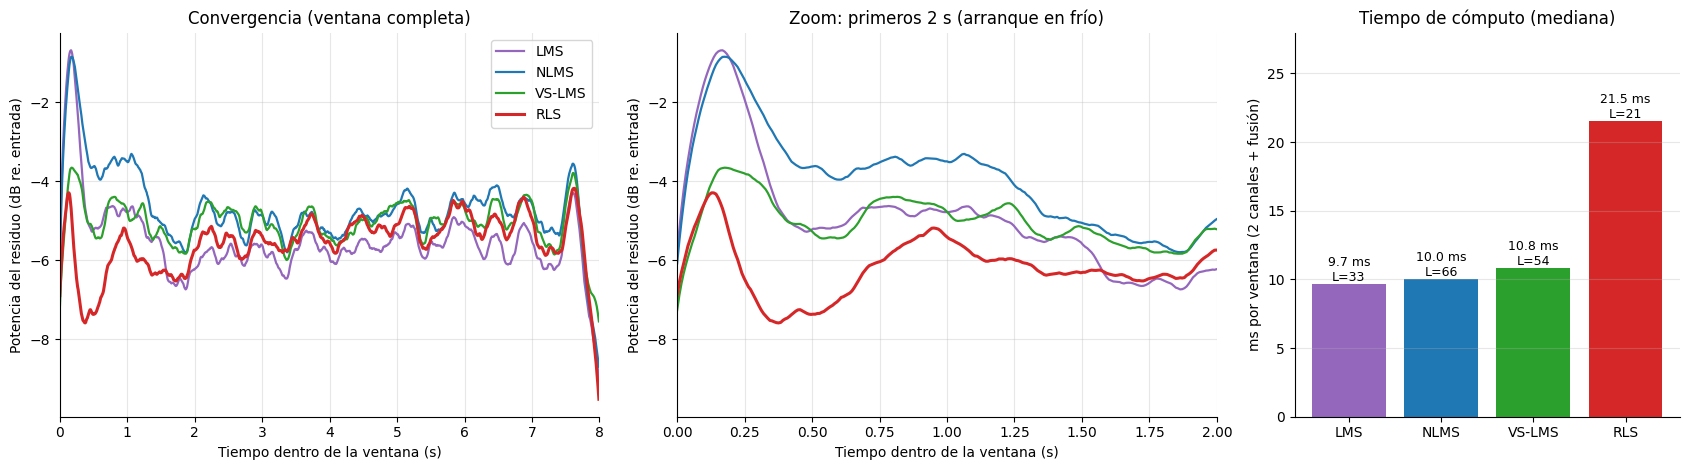

Costo relativo respecto de NLMS: {'LMS': np.float64(1.0), 'NLMS': np.float64(1.0), 'VS-LMS': np.float64(1.1), 'RLS': np.float64(2.1)}


In [9]:
rng = np.random.default_rng(SEED)
curve_idx = rng.choice(len(X_test), size=min(N_CURVE, len(X_test)), replace=False)
pp1, pp2, pacc = preprocess_signal(X_test[curve_idx])

curves, times = {}, {}
for k, model in models.items():
    P, tt = [], []
    for i in range(len(curve_idx)):
        t0 = time.perf_counter()
        _, det = LMSA.lms_bucket(pp1[i], pp2[i], pacc[i], algorithm=model.lms_algorithm, M=model.M,
                                 return_details=True, **model.lms_params)
        tt.append(time.perf_counter() - t0)
        P.append(0.5 * (det["e1"] ** 2 + det["e2"] ** 2))
    curves[k] = np.array(P)
    times[k] = 1e3 * np.median(tt)

t_axis = np.arange(WIN) / FS
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.4, 1.4, 1]})
for ax, tmax in zip(axes[:2], (WIN / FS, 2.0)):
    for k in ["lms", "nlms", "vs_lms", "rls"]:
        med = np.nanmedian(curves[k], axis=0)
        sm = uniform_filter1d(med, size=25, mode="nearest")
        ax.plot(t_axis, 10 * np.log10(sm + 1e-12), color=COLORS[k], lw=2.2 if k == "rls" else 1.6, label=LABELS[k])
    ax.set_xlim(0, tmax)
    ax.set_xlabel("Tiempo dentro de la ventana (s)")
    ax.set_ylabel("Potencia del residuo (dB re. entrada)")
axes[0].set_title("Convergencia (ventana completa)")
axes[1].set_title("Zoom: primeros 2 s (arranque en frío)")
axes[0].legend()

ax = axes[2]
ks = ["lms", "nlms", "vs_lms", "rls"]
Ls = {k: 3 * models[k].M for k in ks}
ax.bar(range(len(ks)), [times[k] for k in ks], color=[COLORS[k] for k in ks])
for j, k in enumerate(ks):
    ax.text(j, times[k], f"{times[k]:.1f} ms\nL={Ls[k]}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(ks)))
ax.set_xticklabels([LABELS[k] for k in ks])
ax.set_ylabel("ms por ventana (2 canales + fusión)")
ax.set_title("Tiempo de cómputo (mediana)")
ax.set_ylim(0, max(times.values()) * 1.3)
ax.grid(axis="x", visible=False)

fig.tight_layout()
save_fig(fig, "05_convergencia_y_costo")
plt.show()
print("Costo relativo respecto de NLMS:", {LABELS[k]: round(times[k] / times["nlms"], 1) for k in ks})

## 8. Casos concretos

Tres ventanas: la **#481** (el outlier del Proyecto 1, donde NLMS y VS-LMS predijeron 36,6 BPM), la ventana donde **RLS más mejora** a la variante LMS de referencia y la donde **más empeora**. Elegir también el peor caso es importante para que la comparación no parezca cherry-picking.

Izquierda: PPG fusionada sin filtrar y señal limpia de cada método (cada una normalizada y desplazada). Derecha: espectros con el BPM real (línea negra) y la estimación de cada método (marcador); todas con el detector común.

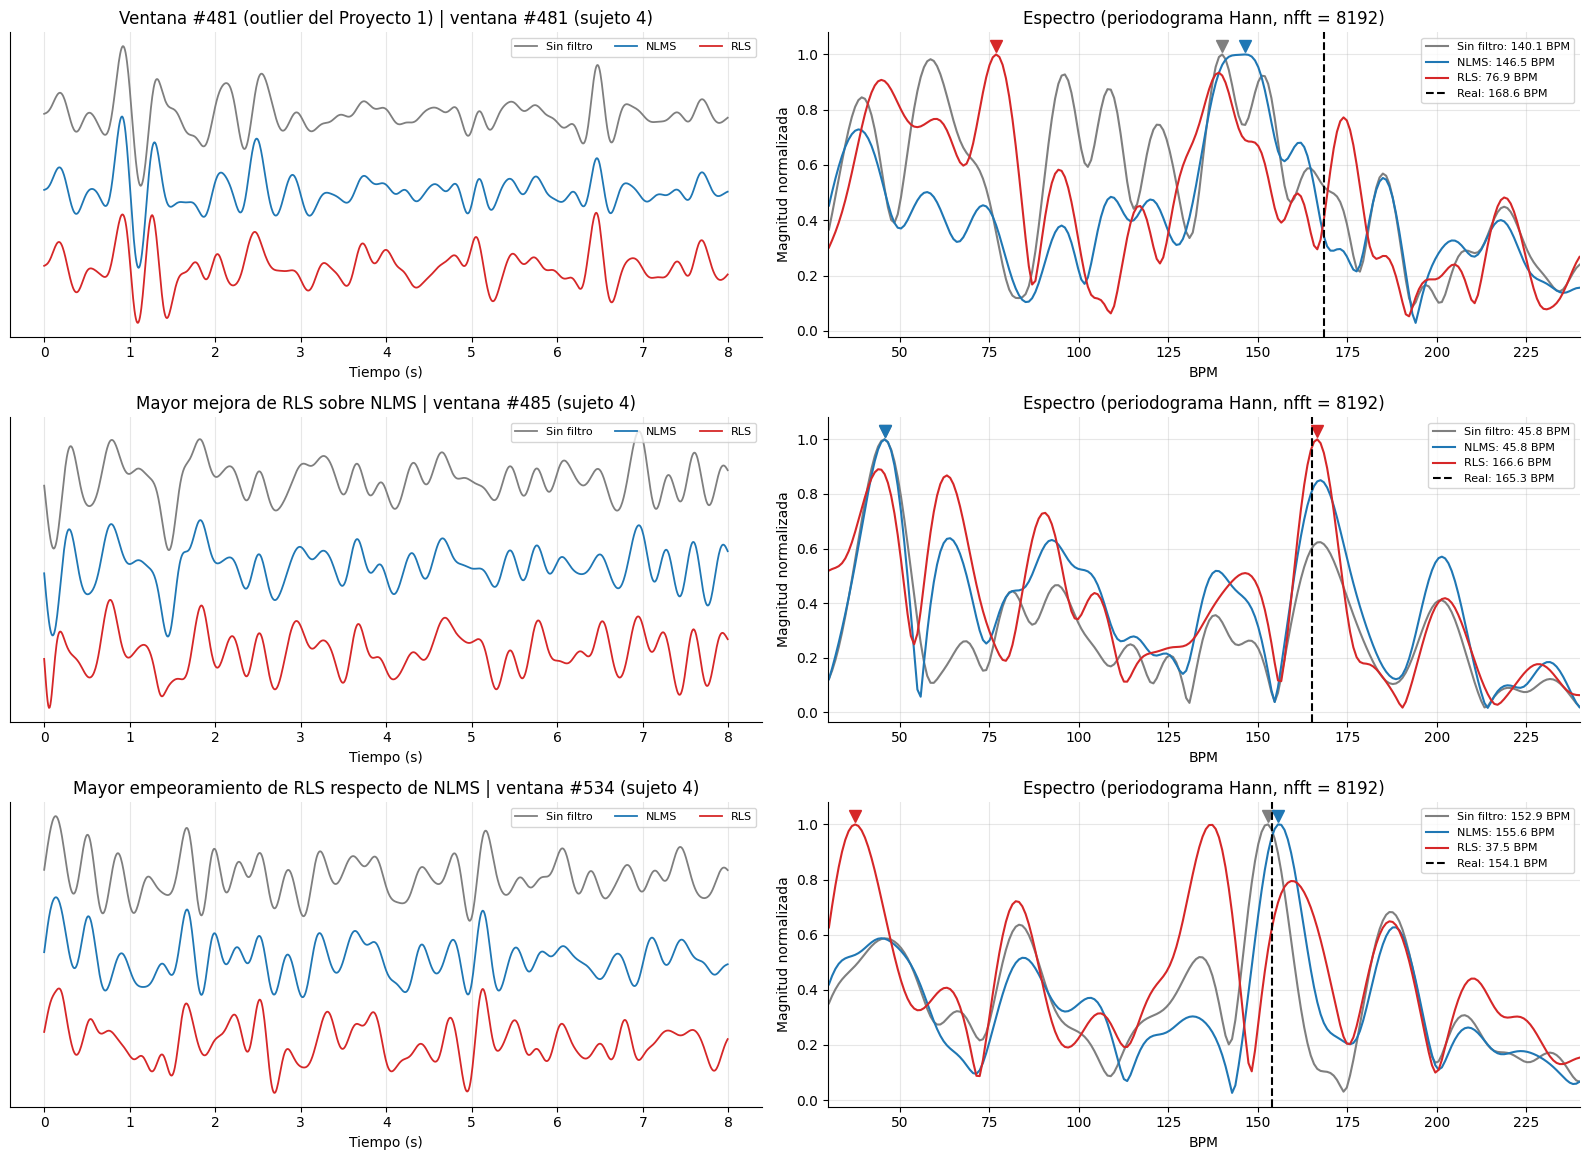

In [10]:
def spectrum_bpm(x, nfft=8192):
    x = np.asarray(x, dtype=float)
    if not np.all(np.isfinite(x)):
        return None, None
    x = x - x.mean()
    X = np.abs(np.fft.rfft(x * np.hanning(len(x)), n=nfft))
    f = np.fft.rfftfreq(nfft, 1.0 / FS)
    m = (f >= 0.5) & (f <= 4.0)
    return 60 * f[m], X[m] / (X[m].max() + 1e-12)


gain_win = test_eval[LMS_REF]["abs_err_common"] - test_eval["rls"]["abs_err_common"]
cases = []
if 481 < len(X_test):
    cases.append((f"Ventana #481 (outlier del Proyecto 1)", 481))
cases.append((f"Mayor mejora de RLS sobre {LABELS[LMS_REF]}", int(np.argmax(gain_win))))
cases.append((f"Mayor empeoramiento de RLS respecto de {LABELS[LMS_REF]}", int(np.argmin(gain_win))))

show = [("base", "Sin filtro"), (LMS_REF, LABELS[LMS_REF]), ("rls", "RLS")]
fig, axes = plt.subplots(len(cases), 2, figsize=(16, 3.9 * len(cases)), squeeze=False)
for r, (title, idx) in enumerate(cases):
    axt, axs = axes[r]
    for j, (k, lab) in enumerate(show):
        sig = test_eval[k]["signals"][idx]
        if np.all(np.isfinite(sig)):
            axt.plot(t_axis, (sig - sig.mean()) / (sig.std() + 1e-12) - 4.2 * j, color=COLORS[k], lw=1.3, label=lab)
        f, S = spectrum_bpm(sig)
        if f is not None:
            axs.plot(f, S, color=COLORS[k], lw=1.5, label=f"{lab}: {test_eval[k]['preds_common'][idx]:.1f} BPM")
            axs.plot(test_eval[k]["preds_common"][idx], 1.03, marker="v", color=COLORS[k], ms=9, clip_on=False)
    axs.axvline(y_test[idx], color="k", lw=1.5, ls="--", label=f"Real: {y_test[idx]:.1f} BPM")
    axt.set_title(f"{title} | ventana #{idx} (sujeto {test_groups[idx] + 1})")
    axt.set_yticks([])
    axt.set_xlabel("Tiempo (s)")
    axt.legend(loc="upper right", fontsize=8, ncol=3)
    axs.set_title("Espectro (periodograma Hann, nfft = 8192)")
    axs.set_xlabel("BPM")
    axs.set_ylabel("Magnitud normalizada")
    axs.set_xlim(30, 240)
    axs.legend(loc="upper right", fontsize=8)
fig.tight_layout()
save_fig(fig, "06_casos_concretos")
plt.show()

## 9. Ablación: ¿la mejora viene de RLS o de lo que se le agregó?

Esta es la pregunta más importante para interpretar los resultados. El RLS del Proyecto 2 cambió **varias cosas a la vez** respecto de los LMS:

1. el algoritmo (RLS en lugar de gradiente estocástico),
2. los **taps dilatados** (`delay_step = 4`, `M = 7`) en lugar de taps consecutivos,
3. regularización inicial fuerte (`delta`), recorte de Huber y carga diagonal.

Para separar los efectos se evalúan variantes sobre **ventanas de entrenamiento** (no de test), todas con el mismo detector (periodograma Hann, nfft = 8192). En particular, **NLMS y VS-LMS con los mismos taps dilatados** muestran cuánto de la mejora se debe a la dilatación y no a RLS. `lms_bucket` ya soporta `delay_step` para cualquier algoritmo.

In [11]:
def prepare_subset(X, n, seed=SEED):
    r = np.random.default_rng(seed)
    idx = np.sort(r.choice(len(X), size=min(n, len(X)), replace=False))
    p1, p2, ac = preprocess_signal(X[idx])
    d_f = np.array([snr_weighted_late_fusion(p1[i], p2[i]) for i in range(len(idx))])
    base = np.array([zero_padded_periodogram_bpm(s, nfft=8192) for s in d_f])
    return idx, p1, p2, ac, base


def eval_filter(algorithm, M, params, subset, y):
    _, p1, p2, ac, base = subset
    preds = np.empty(len(base))
    for i in range(len(base)):
        e = LMSA.lms_bucket(p1[i], p2[i], ac[i], algorithm=algorithm, M=M, return_details=False, **params)
        preds[i] = zero_padded_periodogram_bpm(e, nfft=8192, window_type="hann")
    preds, _ = fill_nan(preds, base)
    err = np.abs(preds - y)
    return dict(aae=err.mean(), medae=np.median(err), out=100 * np.mean(err > OUTLIER_BPM))


if RUN_ABLATION or RUN_SENSITIVITY:
    subset = prepare_subset(X_train, ABL_N)
    y_sub = y_train[subset[0]]
    base_err = np.abs(subset[4] - y_sub)
    print(f"Subconjunto de entrenamiento: {len(y_sub)} ventanas | AAE sin filtro = {base_err.mean():.2f} BPM")

Subconjunto de entrenamiento: 300 ventanas | AAE sin filtro = 13.29 BPM


LMS Proyecto 1 (D=1, M=11)                       AAE=  4.89  mediano= 0.65  outliers=  7.0%   ( 2.6 s)


LMS + Opción B (D=4, M=11, Huber)                AAE=  5.62  mediano= 0.66  outliers=  7.7%   ( 3.0 s)


NLMS Proyecto 1 (D=1, M=22)                      AAE=  5.63  mediano= 0.67  outliers=  7.7%   ( 2.7 s)


NLMS + Opción B (D=4, M=22, Huber)               AAE=  5.06  mediano= 0.67  outliers=  6.7%   ( 3.1 s)


NLMS con taps dilatados (D=4, M=7)               AAE=  5.08  mediano= 0.69  outliers=  7.0%   ( 2.7 s)


VS-LMS Proyecto 1 (D=1, M=18)                    AAE=  6.36  mediano= 0.70  outliers=  9.7%   ( 3.0 s)


... (6 outputs left out)

RLS final sin carga diagonal                     AAE=  3.59  mediano= 0.99  outliers=  4.0%   ( 5.6 s)


RLS final sin olvido (λ=1)                       AAE=  3.37  mediano= 1.01  outliers=  4.3%   ( 5.5 s)


RLS final + warm start (35 %)                    AAE=  3.77  mediano= 1.00  outliers=  5.0%   ( 8.8 s)


RLS final con δ=0.05 (poca regularización)       AAE=  9.48  mediano= 0.80  outliers= 15.0%   ( 6.6 s)


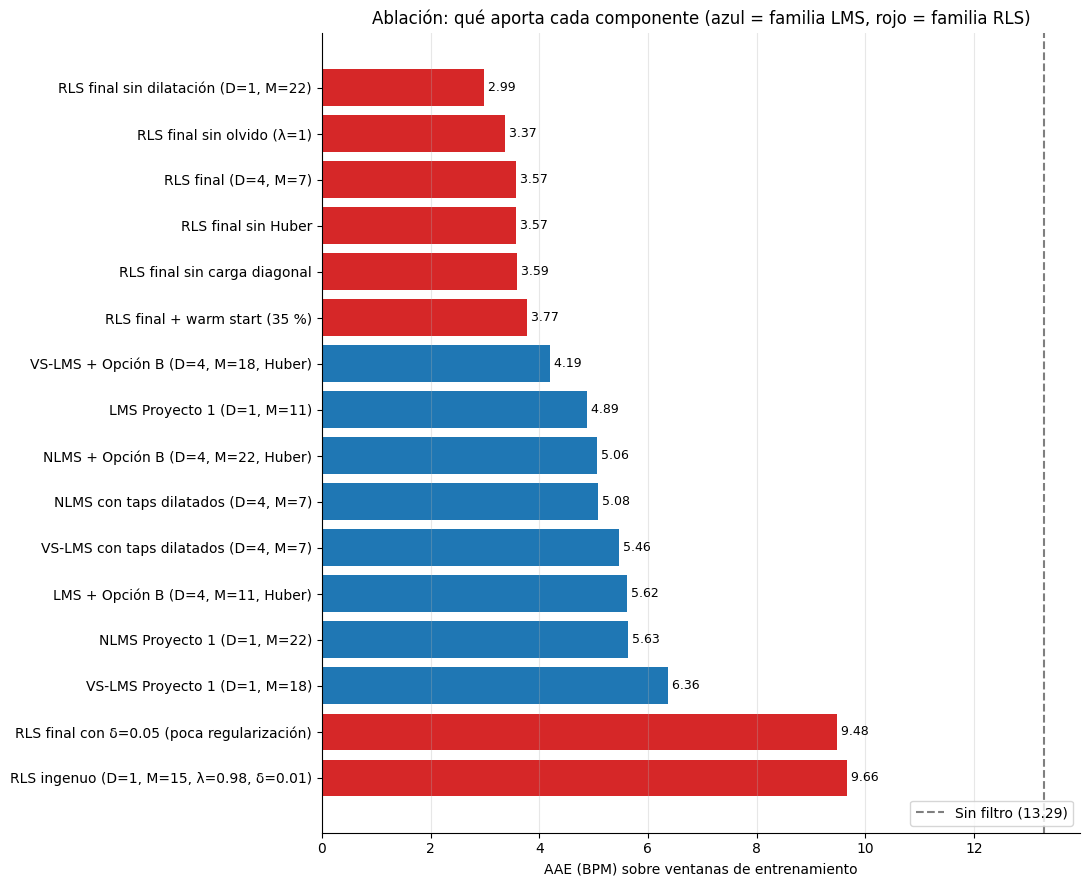

In [12]:
if RUN_ABLATION:
    nlms_p = {"mu": 0.01288, "delta": 0.5}
    vs_p = {k: v for k, v in LMSA.OPTIMAL_VS_LMS_PARAMS.items() if k != "M"}
    rls_full = dict(RLS_PARAMS)

    def rls_with(**over):
        p = dict(rls_full)
        for k, v in over.items():
            if v is None:
                p.pop(k, None)
            else:
                p[k] = v
        return p

    variants = [
        # (nombre, familia, algoritmo, M, parámetros)
        ("LMS Proyecto 1 (D=1, M=11)",                  "lms", "lms",    11, {"mu": 0.00070}),
        ("LMS + Opción B (D=4, M=11, Huber)",           "lms", "lms",    11, {"mu": 0.00070, **SHARED_OPT_B}),
        ("NLMS Proyecto 1 (D=1, M=22)",                 "lms", "nlms",   22, nlms_p),
        ("NLMS + Opción B (D=4, M=22, Huber)",          "lms", "nlms",   22, {**nlms_p, **SHARED_OPT_B}),
        ("NLMS con taps dilatados (D=4, M=7)",          "lms", "nlms",    7, {**nlms_p, "delay_step": 4}),
        ("VS-LMS Proyecto 1 (D=1, M=18)",               "lms", "vs_lms", 18, vs_p),
        ("VS-LMS + Opción B (D=4, M=18, Huber)",        "lms", "vs_lms", 18, {**vs_p, **SHARED_OPT_B}),
        ("VS-LMS con taps dilatados (D=4, M=7)",        "lms", "vs_lms",  7, {**vs_p, "delay_step": 4}),
        ("RLS ingenuo (D=1, M=15, λ=0.98, δ=0.01)",     "rls", "rls",    15, dict(delay_step=1, lam=0.98, delta=0.01, diag_load=0.0, huber_c=0.0, warm_start_ratio=0.0)),
        ("RLS final (D=4, M=7)",                        "rls", "rls", RLS_M, rls_full),
        ("RLS final sin dilatación (D=1, M=22)",        "rls", "rls",    22, rls_with(delay_step=1)),
        ("RLS final sin Huber",                         "rls", "rls", RLS_M, rls_with(huber_c=0.0)),
        ("RLS final sin carga diagonal",                "rls", "rls", RLS_M, rls_with(diag_load=0.0)),
        ("RLS final sin olvido (λ=1)",                  "rls", "rls", RLS_M, rls_with(N_eff=None, lam=1.0)),
        ("RLS final + warm start (35 %)",               "rls", "rls", RLS_M, rls_with(warm_start_ratio=0.35)),
        ("RLS final con δ=0.05 (poca regularización)",  "rls", "rls", RLS_M, rls_with(delta=0.05)),
    ]

    abl = []
    for name, fam, algo, M, params in variants:
        t0 = time.perf_counter()
        r = eval_filter(algo, M, params, subset, y_sub)
        abl.append({"Variante": name, "fam": fam, **r})
        print(f"{name:<48} AAE={r['aae']:6.2f}  mediano={r['medae']:5.2f}  outliers={r['out']:5.1f}%   ({time.perf_counter() - t0:4.1f} s)")
    abl = pd.DataFrame(abl)

    order = abl.sort_values("aae", ascending=False)
    fig, ax = plt.subplots(figsize=(11, 0.46 * len(order) + 1.6))
    cols = [COLORS["rls"] if f == "rls" else COLORS["nlms"] for f in order["fam"]]
    ax.barh(order["Variante"], order["aae"], color=cols)
    for y_, v in enumerate(order["aae"]):
        ax.text(v, y_, f" {v:.2f}", va="center", fontsize=9)
    ax.axvline(base_err.mean(), color="#7f7f7f", ls="--", label=f"Sin filtro ({base_err.mean():.2f})")
    ax.set_xlabel("AAE (BPM) sobre ventanas de entrenamiento")
    ax.set_title("Ablación: qué aporta cada componente (azul = familia LMS, rojo = familia RLS)")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    save_fig(fig, "07_ablacion")
    plt.show()

## 10. Sensibilidad del RLS a la memoria efectiva y a la regularización

Dos barridos con el resto de los hiperparámetros fijos (ventanas de entrenamiento). `N_eff = 1/(1−λ)` es la memoria efectiva en muestras; la ventana tiene 1000, así que `N_eff ≥ 1000` equivale casi a **no olvidar** dentro de la ventana. Si la curva es plana, el rendimiento no depende de ajustar finamente ese parámetro (buena noticia para la robustez del método).

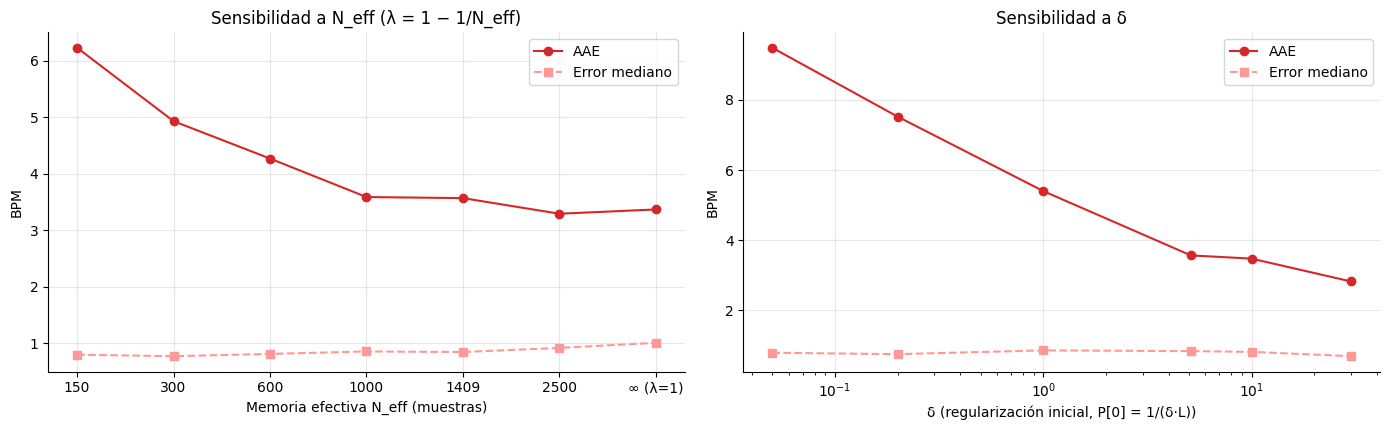

In [13]:
if RUN_SENSITIVITY:
    neffs = [150, 300, 600, 1000, 1409, 2500, np.inf]
    deltas = [0.05, 0.2, 1.0, 5.11, 10.0, 30.0]

    def run(over):
        p = dict(RLS_PARAMS)
        for k, v in over.items():
            if v is None:
                p.pop(k, None)
            else:
                p[k] = v
        return eval_filter("rls", RLS_M, p, subset, y_sub)

    r_neff = [run({"N_eff": None, "lam": 1.0} if np.isinf(n) else {"N_eff": float(n)}) for n in neffs]
    r_delta = [run({"delta": d}) for d in deltas]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
    xs = np.arange(len(neffs))
    axes[0].plot(xs, [r["aae"] for r in r_neff], "o-", color=COLORS["rls"], label="AAE")
    axes[0].plot(xs, [r["medae"] for r in r_neff], "s--", color="#ff9896", label="Error mediano")
    axes[0].set_xticks(xs)
    axes[0].set_xticklabels([("∞ (λ=1)" if np.isinf(n) else f"{n:g}") for n in neffs])
    axes[0].set_xlabel("Memoria efectiva N_eff (muestras)")
    axes[0].set_ylabel("BPM")
    axes[0].set_title("Sensibilidad a N_eff (λ = 1 − 1/N_eff)")
    axes[0].legend()

    axes[1].plot(deltas, [r["aae"] for r in r_delta], "o-", color=COLORS["rls"], label="AAE")
    axes[1].plot(deltas, [r["medae"] for r in r_delta], "s--", color="#ff9896", label="Error mediano")
    axes[1].set_xscale("log")
    axes[1].set_xlabel("δ (regularización inicial, P[0] = 1/(δ·L))")
    axes[1].set_ylabel("BPM")
    axes[1].set_title("Sensibilidad a δ")
    axes[1].legend()

    fig.tight_layout()
    save_fig(fig, "08_sensibilidad_RLS")
    plt.show()

## 11. Resumen automático

Números listos para copiar a la presentación. La interpretación (por qué RLS gana o pierde en cada caso) hay que sacarla de las figuras 05–08, en especial de la **ablación**.

In [14]:
best_lms = min(["lms", "nlms", "vs_lms"], key=lambda k: test_eval[k]["aae"])
b, r_ = test_eval[best_lms], test_eval["rls"]
print("=" * 78)
print("RESUMEN (test, detector propio de cada método)")
print("=" * 78)
print(f"Mejor variante LMS del Proyecto 1 : {LABELS[best_lms]}  (AAE {b['aae']:.2f}, mediano {b['medae']:.2f}, outliers {b['outlier_pct']:.1f}%)")
print(f"RLS (Proyecto 2)                  :      (AAE {r_['aae']:.2f}, mediano {r_['medae']:.2f}, outliers {r_['outlier_pct']:.1f}%)")
print(f"Reducción relativa de AAE         : {100 * (b['aae'] - r_['aae']) / b['aae']:.1f}%")
print(f"Reducción de outliers             : {b['outlier_pct'] - r_['outlier_pct']:.1f} puntos porcentuales")
print(f"Con detector común                : {LABELS[best_lms]} {test_eval[best_lms]['common']['aae']:.2f} vs RLS {test_eval['rls']['common']['aae']:.2f} (AAE)")
print(f"Tiempo por ventana (filtro+fusión): {LABELS[best_lms]} {times[best_lms]:.1f} ms vs RLS {times['rls']:.1f} ms")
print(f"Figuras guardadas en              : {os.path.abspath(FIG_DIR)}")

RESUMEN (test, detector propio de cada método)
Mejor variante LMS del Proyecto 1 : LMS  (AAE 13.09, mediano 1.39, outliers 22.0%)
RLS (Proyecto 2)                  :      (AAE 12.23, mediano 1.44, outliers 21.5%)
Reducción relativa de AAE         : 6.5%
Reducción de outliers             : 0.5 puntos porcentuales
Con detector común                : LMS 13.92 vs RLS 12.23 (AAE)
Tiempo por ventana (filtro+fusión): LMS 9.7 ms vs RLS 21.5 ms
Figuras guardadas en              : /content/ITBA_PAdSA_Proyecto_2/implementation/figuras_comparacion
